# Lab 3: Data Preparation and AI Frameworks
**IC-709D | AI Lab** | NumPy, Pandas, Matplotlib, Scikit-learn

**Aim:** Load a student placement dataset, explore it (EDA), clean it, handle missing values,
encode categories, engineer and select features, visualise it, and build a reusable
preprocessing pipeline. Different preprocessing techniques are compared using model accuracy.

**Dataset:** `placement.csv` (student academic records and placement status). The file used here is a
synthetic dataset created for this lab, with deliberate problems (missing values, duplicates,
inconsistent text, an invalid value and an outlier) so that every cleaning step has something to do.

| Section | Topic |
|---|---|
| 1 | NumPy basics |
| 2 | Dataset loading |
| 3 | Exploratory Data Analysis (EDA) |
| 4 | Data cleaning |
| 5 | Missing value handling (technique comparison) |
| 6 | Label encoding |
| 7 | Feature engineering (impact analysis) |
| 8 | Feature selection |
| 9 | Data visualisation |
| 10 | Application 1: Student Placement Dataset Analysis |
| 11 | Application 2: Data Preprocessing Pipeline |
| 12 | Analysis: scaling techniques comparison |
| 13 | Conclusion and learning outcomes |

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)   # figures are saved here
RANDOM_STATE = 42
print("Libraries loaded.")

Libraries loaded.


## 1. NumPy for numerical computing
NumPy stores numbers in fast arrays. Pandas columns are built on top of NumPy arrays, so these
operations are the foundation of the rest of the lab.

In [2]:
marks = np.array([62.5, 71.0, 58.4, 80.2, 66.7, 74.9])

print("Array        :", marks)
print("Mean         :", marks.mean().round(2))
print("Std deviation:", marks.std().round(2))
print("Min / Max    :", marks.min(), "/", marks.max())
print("75th percentile:", np.percentile(marks, 75))

# Vectorised operations work on the whole array at once (no loop needed)
normalised = (marks - marks.min()) / (marks.max() - marks.min())
print("Min-max normalised:", normalised.round(3))

# 2-D array: 3 students x 2 subjects
table = np.array([[62, 70], [75, 68], [58, 81]])
print("Shape:", table.shape, "| Column means:", table.mean(axis=0))

Array        : [62.5 71.  58.4 80.2 66.7 74.9]
Mean         : 68.95
Std deviation: 7.35
Min / Max    : 58.4 / 80.2
75th percentile: 73.92500000000001
Min-max normalised: [0.188 0.578 0.    1.    0.381 0.757]
Shape: (3, 2) | Column means: [65. 73.]


## 2. Dataset loading
The loader tries a few common locations (the shared `datasets/` folder of the repository, or the
current folder). In Google Colab, upload `placement.csv` using the Files panel first.

In [3]:
def load_dataset(candidate_paths):
    """Return the CSV from the first path that exists."""
    for path in candidate_paths:
        if os.path.exists(path):
            print(f"Loaded dataset from: {path}")
            return pd.read_csv(path)
    raise FileNotFoundError(
        "placement.csv not found. Put it in ../datasets/ or upload it to the current folder.")


df_raw = load_dataset(["../datasets/placement.csv", "datasets/placement.csv", "placement.csv"])
df = df_raw.copy()          # keep the raw data untouched
print("Shape (rows, columns):", df.shape)
df.head(8)

Loaded dataset from: placement.csv
Shape (rows, columns): (220, 12)


,student_id,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_type,work_experience,etest_percentage,specialisation,mba_percentage,status,salary
0,1,F,53.74,74.84,70.89,Sci&Tech,No,85.69,Mkt&HR,73.42,Placed,293000.0
1,2,M,67.31,84.93,80.37,Comm&Mgmt,Yes,90.90,Mkt&Fin,59.28,Placed,300000.0
2,3,F,62.16,50.80,67.20,Sci&Tech,No,73.83,Mkt&Fin,63.56,Not Placed,NaN
3,4,F,63.72,70.32,63.64,Others,Yes,72.36,Mkt&HR,68.15,Placed,301000.0
4,5,M,77.03,54.55,65.01,Sci&Tech,No,50.26,Mkt&HR,61.02,Not Placed,NaN
5,6,F,72.38,71.22,70.31,Sci&Tech,No,87.76,Mkt&HR,58.51,Placed,940000.0
6,7,F,80.37,64.56,53.89,Comm&Mgmt,Yes,65.87,Mkt&Fin,51.00,Not Placed,NaN
7,8,F,650.00,45.86,67.15,Comm&Mgmt,Yes,92.18,Mkt&HR,65.85,Not Placed,NaN


## 3. Exploratory Data Analysis (EDA)
Before changing anything, look at the structure, data types, summary statistics, missing values
and duplicates.

In [4]:
print("Columns:", list(df.columns))
print()
df.info()

Columns: ['student_id', 'gender', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'degree_type', 'work_experience', 'etest_percentage', 'specialisation', 'mba_percentage', 'status', 'salary']

<class 'pandas.DataFrame'>
RangeIndex: 220 entries, 0 to 219
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   student_id         220 non-null    int64  
 1   gender             220 non-null    str    
 2   ssc_percentage     220 non-null    float64
 3   hsc_percentage     213 non-null    float64
 4   degree_percentage  212 non-null    float64
 5   degree_type        215 non-null    str    
 6   work_experience    220 non-null    str    
 7   etest_percentage   210 non-null    float64
 8   specialisation     220 non-null    str    
 9   mba_percentage     220 non-null    float64
 10  status             220 non-null    str    
 11  salary             129 non-null    float64
dtypes: float64(6), int64(1), st

In [5]:
print("Numeric summary")
df.describe().round(2)

Numeric summary


,student_id,ssc_percentage,hsc_percentage,degree_percentage,etest_percentage,mba_percentage,salary
count,220.00,220.00,213.00,212.00,210.00,220.00,129.00
mean,108.20,69.58,65.06,66.08,74.39,61.35,289992.25
std,61.98,40.57,11.26,6.94,14.20,5.75,76650.33
min,1.00,41.33,40.00,50.00,50.26,51.00,200000.00
25%,54.75,60.04,56.91,61.05,60.95,57.33,250000.00
50%,108.00,67.53,65.05,66.15,73.59,61.60,286000.00
75%,161.25,73.54,71.95,70.49,87.50,65.66,315000.00
max,215.00,650.00,94.57,88.25,97.75,78.00,940000.00


In [6]:
print("Categorical summary")
df.describe(include="object")

Categorical summary


,gender,degree_type,work_experience,specialisation,status
count,220,215,220,220,220
unique,3,3,2,4,2
top,M,Comm&Mgmt,No,Mkt&Fin,Placed
freq,138,108,143,113,129


In [7]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print()
print("Duplicate rows:", df.duplicated().sum())
print()
print("Target distribution (status):")
print(df["status"].value_counts())
print()
for column in ["gender", "degree_type", "work_experience", "specialisation"]:
    print(f"{column} ->", df[column].value_counts(dropna=False).to_dict())

Missing values per column:
hsc_percentage        7
degree_percentage     8
degree_type           5
etest_percentage     10
salary               91
dtype: int64

Duplicate rows: 5

Target distribution (status):
status
Placed        129
Not Placed     91
Name: count, dtype: int64

gender -> {'M': 138, 'F': 78, 'm': 4}
degree_type -> {'Comm&Mgmt': 108, 'Sci&Tech': 81, 'Others': 26, nan: 5}
work_experience -> {'No': 143, 'Yes': 77}
specialisation -> {'Mkt&Fin': 113, 'Mkt&HR': 103, 'Mkt&Fin ': 3, 'Mkt&HR ': 1}


**Problems found in the raw data**
- Missing values in `hsc_percentage`, `degree_percentage`, `degree_type` and `etest_percentage`.
- Duplicate rows.
- Inconsistent text: `gender` has both `M` and `m`, and `specialisation` has values with a trailing space.
- An impossible percentage (the `max` of `ssc_percentage` is far above 100).
- `salary` is empty for students who were not placed (this is expected, not an error).
- `student_id` is only an identifier and carries no information for prediction.

## 4. Data cleaning

In [8]:
df_clean = df_raw.copy()
rows_before = len(df_clean)

# 1) Remove duplicate rows
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", rows_before - len(df_clean))

# 2) Fix inconsistent text (trim spaces, make gender upper-case)
df_clean["specialisation"] = df_clean["specialisation"].str.strip()
df_clean["gender"] = df_clean["gender"].str.strip().str.upper()
print("Gender values:", df_clean["gender"].unique(), "| Specialisation values:",
      df_clean["specialisation"].unique())

# 3) Invalid percentages (outside 0-100) are treated as missing
percentage_columns = [c for c in df_clean.columns if c.endswith("_percentage")]
for column in percentage_columns:
    invalid = ~df_clean[column].between(0, 100) & df_clean[column].notna()
    if invalid.any():
        print(f"Invalid values in {column}:", df_clean.loc[invalid, column].tolist(), "-> set to NaN")
        df_clean.loc[invalid, column] = np.nan

# 4) Drop the identifier column (no predictive value)
df_clean = df_clean.drop(columns=["student_id"])

print("\nShape after cleaning:", df_clean.shape)

Duplicates removed: 5
Gender values: <StringArray>
['F', 'M']
Length: 2, dtype: str | Specialisation values: <StringArray>
['Mkt&HR', 'Mkt&Fin']
Length: 2, dtype: str
Invalid values in ssc_percentage: [650.0] -> set to NaN

Shape after cleaning: (215, 11)


In [9]:
# 5) Salary outliers (IQR rule) - checked only for placed students
placed_salary = df_clean["salary"].dropna()
q1, q3 = placed_salary.quantile([0.25, 0.75])
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
outliers = placed_salary[placed_salary > upper_limit]
print(f"IQR upper limit: {upper_limit:,.0f}")
print("Salary outliers:", outliers.tolist())

# Cap (winsorise) instead of deleting the student record
df_clean["salary"] = df_clean["salary"].clip(upper=upper_limit)
print("Max salary after capping:", df_clean["salary"].max())

IQR upper limit: 413,750
Salary outliers: [940000.0]
Max salary after capping: 413750.0


## 5. Missing value handling
**Salary** is missing only for `Not Placed` students, so it is *structurally* missing and must not
be filled in. We confirm this below.

For the real missing values (`hsc_percentage`, `degree_percentage`, `etest_percentage`, `degree_type`, and the one invalid `ssc_percentage` turned into a missing value during cleaning)
several techniques exist. Each technique is compared using 5-fold cross-validated accuracy of a
Logistic Regression model. The imputer sits inside the pipeline, so it is fitted only on training
folds (no data leakage).

In [10]:
print("Salary missing for Not Placed only:",
      df_clean.loc[df_clean["salary"].isna(), "status"].unique())
print("\nMissing values (columns used for prediction):")
print(df_clean.drop(columns="salary").isna().sum()[lambda s: s > 0])

Salary missing for Not Placed only: <StringArray>
['Not Placed']
Length: 1, dtype: str

Missing values (columns used for prediction):
ssc_percentage        1
hsc_percentage        6
degree_percentage     8
degree_type           5
etest_percentage     10
dtype: int64


In [11]:
NUMERIC_COLS = ["ssc_percentage", "hsc_percentage", "degree_percentage",
                "etest_percentage", "mba_percentage"]
CATEGORICAL_COLS = ["gender", "degree_type", "work_experience", "specialisation"]
TARGET = "status"


def make_preprocessor(numeric_imputer, scaler="standard",
                      numeric_cols=NUMERIC_COLS, categorical_cols=CATEGORICAL_COLS):
    """Numeric: impute + scale. Categorical: fill with mode + one-hot encode."""
    scalers = {"standard": StandardScaler(), "minmax": MinMaxScaler(), "none": "passthrough"}
    numeric_pipe = Pipeline([("imputer", numeric_imputer), ("scaler", scalers[scaler])])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([("num", numeric_pipe, numeric_cols),
                              ("cat", categorical_pipe, categorical_cols)])


def cv_accuracy(model, X, y, folds=5):
    """Mean and std of stratified k-fold accuracy."""
    splitter = StratifiedKFold(n_splits=folds, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(model, X, y, cv=splitter, scoring="accuracy")
    return scores.mean(), scores.std()


strategies = {
    "Drop rows with missing": None,
    "Mean imputation": SimpleImputer(strategy="mean"),
    "Median imputation": SimpleImputer(strategy="median"),
    "KNN imputation (k=5)": KNNImputer(n_neighbors=5),
}

feature_cols = NUMERIC_COLS + CATEGORICAL_COLS
rows = []
for name, imputer in strategies.items():
    if imputer is None:
        data = df_clean.dropna(subset=feature_cols)
        imputer = SimpleImputer(strategy="median")      # nothing left to impute
    else:
        data = df_clean
    model = Pipeline([("prep", make_preprocessor(imputer)),
                      ("clf", LogisticRegression(max_iter=1000))])
    mean_acc, std_acc = cv_accuracy(model, data[feature_cols], data[TARGET])
    rows.append({"Technique": name, "Rows used": len(data),
                 "CV Accuracy": round(mean_acc, 4), "Std": round(std_acc, 4)})

missing_comparison = pd.DataFrame(rows)
missing_comparison

,Technique,Rows used,CV Accuracy,Std
0,Drop rows with missing,187,0.6841,0.0643
1,Mean imputation,215,0.6884,0.0522
2,Median imputation,215,0.6930,0.0577
3,KNN imputation (k=5),215,0.6977,0.0624


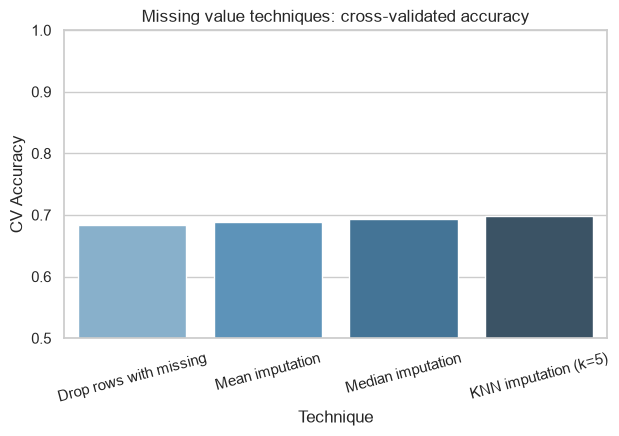

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=missing_comparison, x="Technique", y="CV Accuracy", ax=ax, palette="Blues_d")
ax.set_ylim(0.5, 1.0)
ax.set_title("Missing value techniques: cross-validated accuracy")
ax.tick_params(axis="x", rotation=15)
plt.savefig("outputs/missing_value_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** the four techniques give very similar accuracy (about 0.68 to 0.70). The differences are much smaller than the standard deviation across folds (about 0.05 to 0.06), so no technique is clearly better than the others on this dataset.

**Why imputation is still preferred over dropping rows:** dropping rows removed 28 students (215 to 187, about 13% of the data) for no gain. Median imputation is a safe default because the median is not pulled by extreme values. KNN imputation scores slightly higher here, but it is slower and more complex, and with so few missing values the gain is not reliable.

**Decision:** median imputation for numeric columns and most-frequent (mode) for categorical columns.

## 6. Label encoding
Models need numbers, not text. `LabelEncoder` converts each category into an integer.
It is suitable for the **target** and for **binary** columns. For a column with several
unordered categories (`degree_type`) label encoding creates a false order (0 < 1 < 2), so
**one-hot encoding** is used for that column instead.

In [13]:
df_encoded = df_clean.copy()
mappings = {}

for column in ["gender", "work_experience", "specialisation", "status"]:
    encoder = LabelEncoder()
    df_encoded[column] = encoder.fit_transform(df_encoded[column])
    mappings[column] = {label: int(code) for code, label in enumerate(encoder.classes_)}

for column, mapping in mappings.items():
    print(f"{column:<17}: {mapping}")

print()
df_encoded[["gender", "work_experience", "specialisation", "status"]].head()

gender           : {'F': 0, 'M': 1}
work_experience  : {'No': 0, 'Yes': 1}
specialisation   : {'Mkt&Fin': 0, 'Mkt&HR': 1}
status           : {'Not Placed': 0, 'Placed': 1}



,gender,work_experience,specialisation,status
0,0,0,1,1
1,1,1,0,1
2,0,0,0,0
3,0,1,1,1
4,1,0,1,0


In [14]:
# One-hot encoding for the multi-category column (NaN kept as its own gap, filled later)
pd.get_dummies(df_clean["degree_type"], prefix="degree_type").astype(int).head()

,degree_type_Comm&Mgmt,degree_type_Others,degree_type_Sci&Tech
0,0,0,1
1,1,0,0
2,0,0,1
3,0,1,0
4,0,0,1


## 7. Feature engineering
New features are created from existing ones:

| New feature | Meaning |
|---|---|
| `avg_academic_pct` | Mean of SSC, HSC, degree and MBA percentages |
| `academic_consistency` | Standard deviation of those four percentages (lower = more consistent) |
| `exp_etest_interaction` | Work experience (0/1) multiplied by the employability test score |

Impact is measured by comparing cross-validated accuracy **with and without** the new features,
for two different models.

In [15]:
df_fe = df_clean.copy()
academic_cols = ["ssc_percentage", "hsc_percentage", "degree_percentage", "mba_percentage"]

df_fe["avg_academic_pct"] = df_fe[academic_cols].mean(axis=1)
df_fe["academic_consistency"] = df_fe[academic_cols].std(axis=1)
df_fe["exp_etest_interaction"] = (df_fe["work_experience"] == "Yes").astype(int) * df_fe["etest_percentage"]

ENGINEERED_COLS = ["avg_academic_pct", "academic_consistency", "exp_etest_interaction"]
df_fe[ENGINEERED_COLS].describe().round(2)

,avg_academic_pct,academic_consistency,exp_etest_interaction
count,215.00,215.00,205.00
mean,64.87,8.29,27.49
std,4.50,3.67,37.29
min,51.21,1.26,0.00
25%,62.49,5.40,0.00
50%,64.80,7.89,0.00
75%,68.11,10.63,64.58
max,79.38,19.17,97.75


In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}
median_imputer = SimpleImputer(strategy="median")

rows = []
for model_name, estimator in models.items():
    for label, numeric_cols in [("Without engineered features", NUMERIC_COLS),
                                ("With engineered features", NUMERIC_COLS + ENGINEERED_COLS)]:
        pipeline = Pipeline([
            ("prep", make_preprocessor(median_imputer, numeric_cols=numeric_cols)),
            ("clf", estimator)])
        mean_acc, std_acc = cv_accuracy(pipeline, df_fe[numeric_cols + CATEGORICAL_COLS], df_fe[TARGET])
        rows.append({"Model": model_name, "Features": label,
                     "CV Accuracy": round(mean_acc, 4), "Std": round(std_acc, 4)})

fe_comparison = pd.DataFrame(rows)
fe_comparison

,Model,Features,CV Accuracy,Std
0,Logistic Regression,Without engineered features,0.6930,0.0577
1,Logistic Regression,With engineered features,0.7116,0.0634
2,Decision Tree,Without engineered features,0.6419,0.0926
3,Decision Tree,With engineered features,0.6186,0.0479


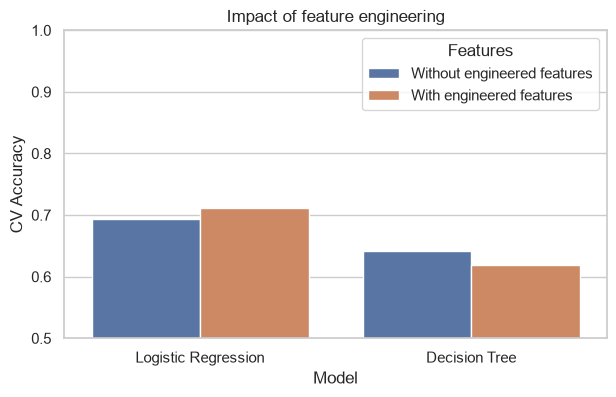

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=fe_comparison, x="Model", y="CV Accuracy", hue="Features", ax=ax)
ax.set_ylim(0.5, 1.0)
ax.set_title("Impact of feature engineering")
plt.savefig("outputs/feature_engineering_impact.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** for Logistic Regression accuracy rose from 0.693 to 0.712, but for the Decision Tree it fell from 0.642 to 0.619. Both changes are smaller than the fold-to-fold standard deviation (about 0.05 to 0.09), so the engineered features did **not** give a reliable improvement here.

**Useful point:** `avg_academic_pct` combines four weak signals into one stronger signal (it gets the highest F-score in Section 8), which is why it can help a linear model. A tree can already split on the original columns, so the extra features add noise more than information.

**Lesson:** keep a new feature only if it improves a cross-validated score, not just because it sounds sensible.

## 8. Feature selection
Two statistical scores rank the features by how strongly they relate to `status`:
**ANOVA F-score** (linear relationship) and **mutual information** (any relationship).

In [18]:
preprocessor = make_preprocessor(median_imputer, scaler="none",
                                 numeric_cols=NUMERIC_COLS + ENGINEERED_COLS)
X_all = preprocessor.fit_transform(df_fe[NUMERIC_COLS + ENGINEERED_COLS + CATEGORICAL_COLS])
feature_names = [name.split("__")[-1] for name in preprocessor.get_feature_names_out()]
X_all = pd.DataFrame(X_all, columns=feature_names)
y_all = df_fe[TARGET]

f_scores, _ = f_classif(X_all, y_all)
mi_scores = mutual_info_classif(X_all, y_all, random_state=RANDOM_STATE)

ranking = pd.DataFrame({"Feature": feature_names, "F-score": f_scores.round(2),
                        "Mutual info": mi_scores.round(3)})
ranking = ranking.sort_values("F-score", ascending=False).reset_index(drop=True)
ranking

,Feature,F-score,Mutual info
0,avg_academic_pct,44.34,0.146
1,ssc_percentage,20.91,0.000
2,mba_percentage,20.89,0.012
3,hsc_percentage,4.68,0.032
4,degree_percentage,4.60,0.000
5,exp_etest_interaction,3.37,0.003
6,degree_type_Sci&Tech,2.73,0.000
7,work_experience_No,2.55,0.000
8,work_experience_Yes,2.55,0.000
9,gender_F,1.68,0.062


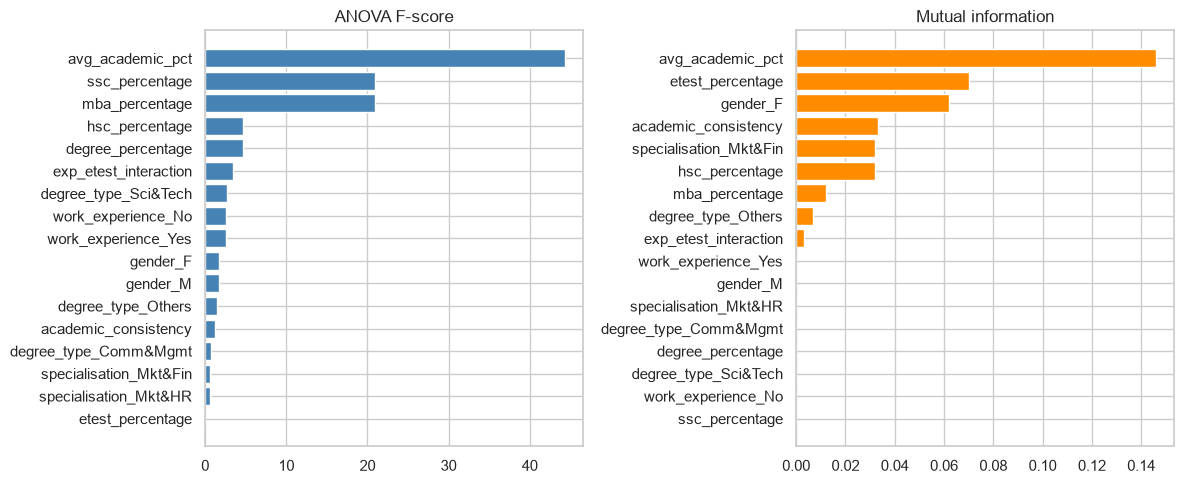

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top = ranking.sort_values("F-score")
axes[0].barh(top["Feature"], top["F-score"], color="steelblue")
axes[0].set_title("ANOVA F-score")
top = ranking.sort_values("Mutual info")
axes[1].barh(top["Feature"], top["Mutual info"], color="darkorange")
axes[1].set_title("Mutual information")
plt.tight_layout()
plt.savefig("outputs/feature_importance_scores.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# Does keeping only the top-k features change accuracy? (selection is inside the pipeline)
numeric_all = NUMERIC_COLS + ENGINEERED_COLS
rows = []
total_features = X_all.shape[1]
for k in [3, 5, 8, total_features]:
    pipeline = Pipeline([
        ("prep", make_preprocessor(median_imputer, numeric_cols=numeric_all)),
        ("select", SelectKBest(f_classif, k=k)),
        ("clf", LogisticRegression(max_iter=1000))])
    mean_acc, std_acc = cv_accuracy(pipeline, df_fe[numeric_all + CATEGORICAL_COLS], df_fe[TARGET])
    label = f"Top {k}" if k != total_features else f"All {k}"
    rows.append({"Features kept": label, "CV Accuracy": round(mean_acc, 4), "Std": round(std_acc, 4)})

selection_comparison = pd.DataFrame(rows)
selection_comparison

,Features kept,CV Accuracy,Std
0,Top 3,0.6791,0.0648
1,Top 5,0.6837,0.0668
2,Top 8,0.6884,0.0730
3,All 17,0.7116,0.0634


**Observation:** `avg_academic_pct` has the highest F-score (44.3), followed by `ssc_percentage` and `mba_percentage` (about 20.9 each). `etest_percentage` has an F-score of 0, so it has no linear relationship with placement in this dataset. Some mutual-information values are 0 or very small because mutual information is unreliable on only 215 rows.

**Top-k test:** accuracy is highest when all 17 features are kept (0.712) and lower for the top 3, 5 and 8 (0.679 to 0.688). The gaps are within the standard deviation, so selection did not help here. With a small dataset and a simple model, removing features does not make the model better.

**Note:** after one-hot encoding, the two columns of a binary feature (for example `work_experience_No` and `work_experience_Yes`) carry the same information, so they get identical scores.

## 9. Data visualisation

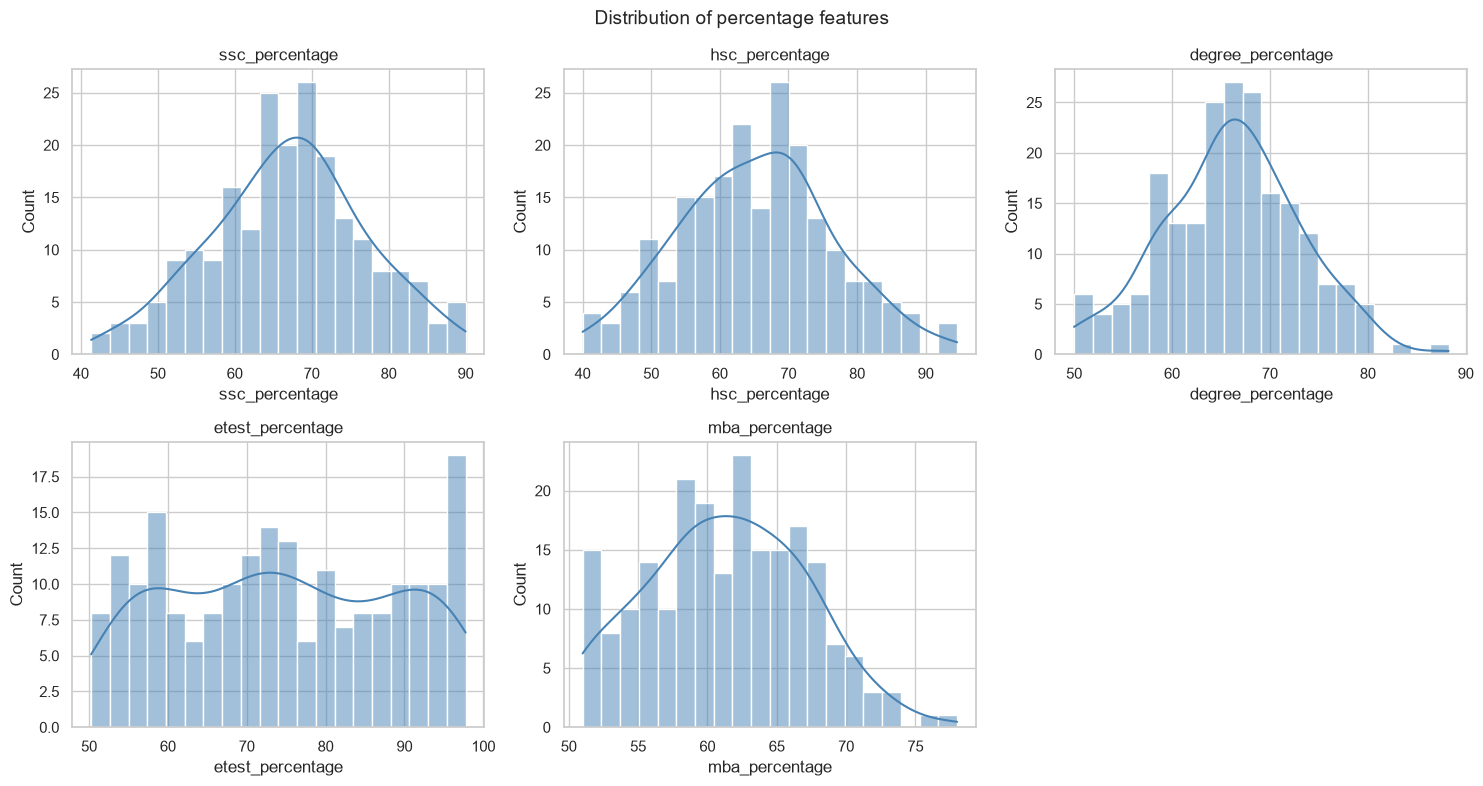

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.ravel(), NUMERIC_COLS):
    sns.histplot(df_clean[column], bins=20, kde=True, ax=ax, color="steelblue")
    ax.set_title(column)
axes.ravel()[-1].axis("off")
plt.suptitle("Distribution of percentage features", fontsize=14)
plt.tight_layout()
plt.savefig("outputs/histograms.png", dpi=150, bbox_inches="tight")
plt.show()

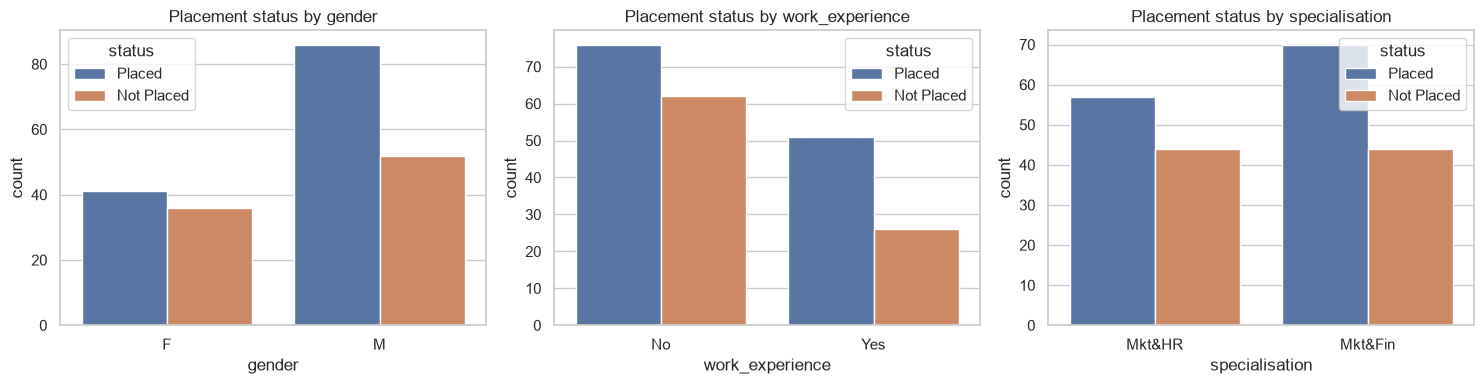

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["gender", "work_experience", "specialisation"]):
    sns.countplot(data=df_clean, x=column, hue="status", ax=ax)
    ax.set_title(f"Placement status by {column}")
plt.tight_layout()
plt.savefig("outputs/countplots_status.png", dpi=150, bbox_inches="tight")
plt.show()

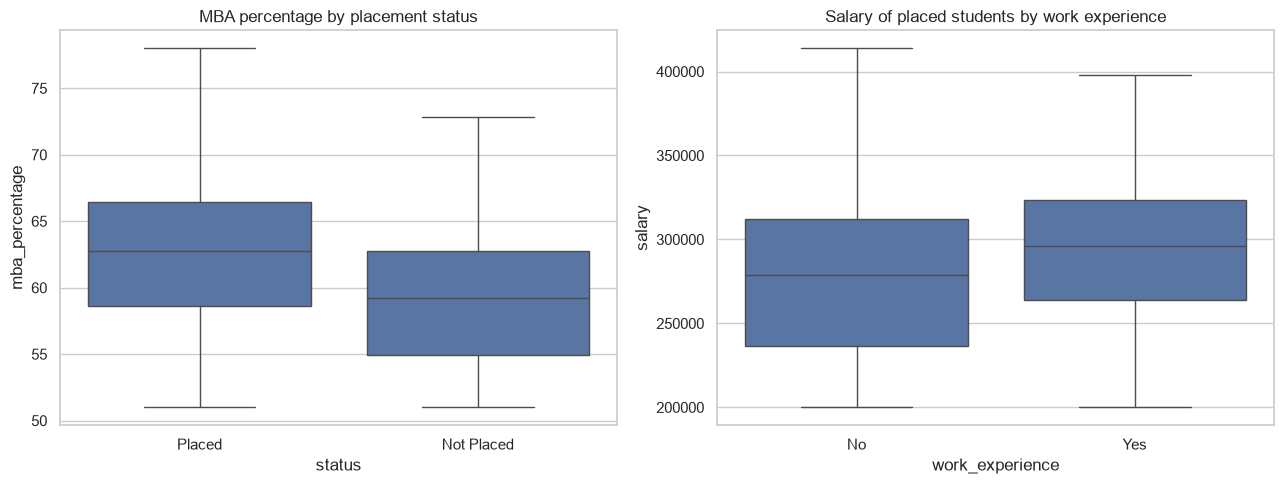

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df_clean, x="status", y="mba_percentage", ax=axes[0])
axes[0].set_title("MBA percentage by placement status")
sns.boxplot(data=df_clean.dropna(subset=["salary"]), x="work_experience", y="salary", ax=axes[1])
axes[1].set_title("Salary of placed students by work experience")
plt.tight_layout()
plt.savefig("outputs/boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

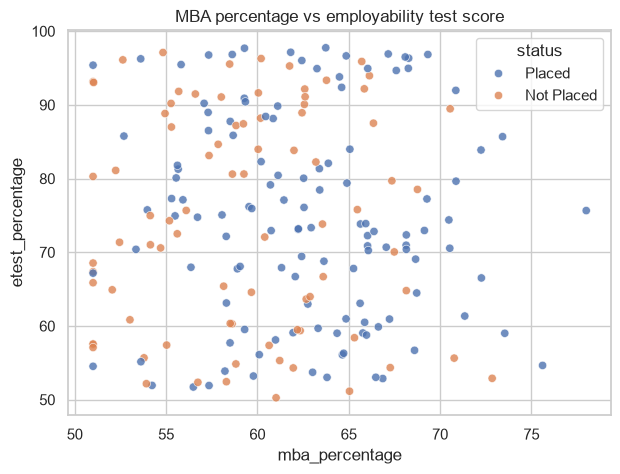

In [24]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="mba_percentage", y="etest_percentage", hue="status", alpha=0.8)
plt.title("MBA percentage vs employability test score")
plt.savefig("outputs/scatter_mba_etest.png", dpi=150, bbox_inches="tight")
plt.show()

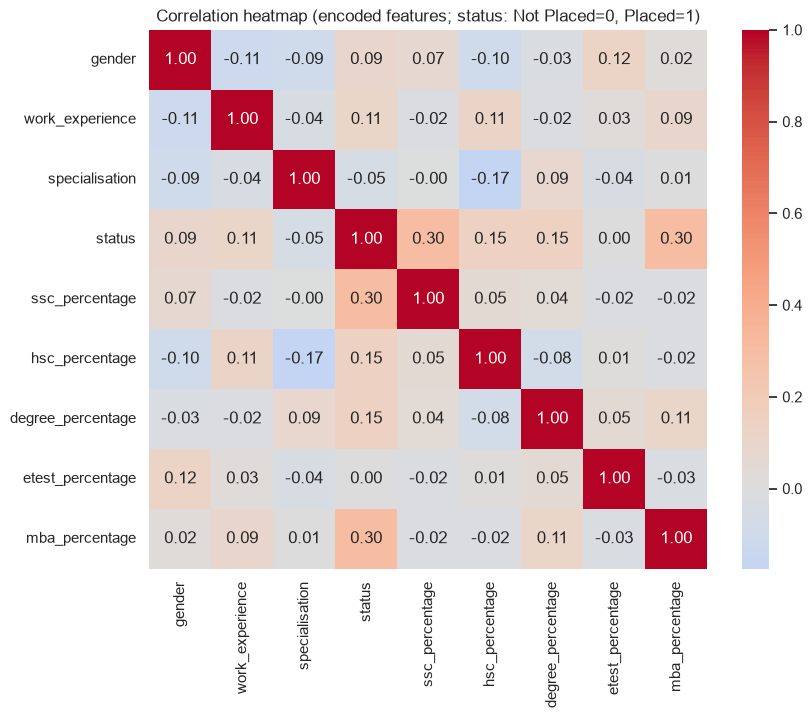

In [25]:
numeric_for_corr = df_encoded[["gender", "work_experience", "specialisation", "status"]].join(
    df_clean[NUMERIC_COLS])
plt.figure(figsize=(9, 7))
sns.heatmap(numeric_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap (encoded features; status: Not Placed=0, Placed=1)")
plt.savefig("outputs/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Application 1: Student Placement Dataset Analysis

In [26]:
placement_rate = (df_clean["status"] == "Placed").mean() * 100
print(f"Overall placement rate: {placement_rate:.1f}% "
      f"({(df_clean['status'] == 'Placed').sum()} of {len(df_clean)} students)\n")

for column in ["gender", "work_experience", "specialisation", "degree_type"]:
    rate = (df_clean.groupby(column)["status"].apply(lambda s: (s == "Placed").mean() * 100)
            .round(1).rename("Placement rate (%)"))
    print(rate.to_string(), "\n")

Overall placement rate: 59.1% (127 of 215 students)

gender
F    53.2
M    62.3 

work_experience
No     55.1
Yes    66.2 

specialisation
Mkt&Fin    61.4
Mkt&HR     56.4 

degree_type
Comm&Mgmt    54.3
Others       48.0
Sci&Tech     66.2 



In [27]:
print("Average percentages: Placed vs Not Placed")
df_clean.groupby("status")[NUMERIC_COLS].mean().round(2).T

Average percentages: Placed vs Not Placed


status,Not Placed,Placed
ssc_percentage,63.31,69.47
hsc_percentage,63.30,66.66
degree_percentage,64.84,66.95
etest_percentage,74.63,74.69
mba_percentage,59.26,62.73


In [28]:
placed = df_clean[df_clean["status"] == "Placed"]
print("Salary statistics (placed students):")
print(placed["salary"].describe().round(0).to_string())
print()
print("Average salary by work experience:")
print(placed.groupby("work_experience")["salary"].mean().round(0).to_string())
print()
print("Average salary by specialisation:")
print(placed.groupby("specialisation")["salary"].mean().round(0).to_string())

Salary statistics (placed students):
count       127.0
mean     286297.0
std       52059.0
min      200000.0
25%      250000.0
50%      287000.0
75%      315500.0
max      413750.0

Average salary by work experience:
work_experience
No     279628.0
Yes    296235.0

Average salary by specialisation:
specialisation
Mkt&Fin    292700.0
Mkt&HR     278434.0


**Key findings (for this dataset)**
- Overall placement rate is 59.1% (127 of 215 students).
- Students with work experience were placed more often (66.2% vs 55.1%) and have a higher average salary (about 296,000 vs 280,000).
- `Sci&Tech` degree students have the highest placement rate (66.2%). `Others` is lowest (48.0%) but contains very few students, so it rests on little data.
- Placed students have higher average SSC (69.5 vs 63.3) and MBA (62.7 vs 59.3) percentages. The employability test score is almost identical for both groups (74.7 vs 74.6), so it does not separate them here.
- `Mkt&Fin` students are placed slightly more often and have a higher average salary than `Mkt&HR`.

**Caution:** group differences come from small samples and show association, not cause. The dataset is synthetic, so these are findings about this file, not about real students.

## 11. Application 2: Data Preprocessing Pipeline
All steps are combined in one scikit-learn `Pipeline`: impute missing values, scale numeric
columns, one-hot encode categories, then train a model. The data is split **first** (80% train,
20% test, stratified), so the imputer and scaler learn only from the training set.

In [29]:
X = df_fe[NUMERIC_COLS + CATEGORICAL_COLS]
y = df_fe[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train size:", len(X_train), "| Test size:", len(X_test))

final_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}

fitted = {}
rows = []
for name, estimator in final_models.items():
    pipeline = Pipeline([("prep", make_preprocessor(SimpleImputer(strategy="median"))),
                         ("clf", estimator)])
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    train_time = time.perf_counter() - start
    predictions = pipeline.predict(X_test)
    fitted[name] = (pipeline, predictions)
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Precision": round(precision_score(y_test, predictions, pos_label="Placed"), 4),
        "Recall": round(recall_score(y_test, predictions, pos_label="Placed"), 4),
        "F1-score": round(f1_score(y_test, predictions, pos_label="Placed"), 4),
        "Train time (s)": round(train_time, 4)})

pipeline_results = pd.DataFrame(rows)
pipeline_results

Train size: 172 | Test size: 43


,Model,Accuracy,Precision,Recall,F1-score,Train time (s)
0,Logistic Regression,0.6279,0.6364,0.84,0.7241,0.0413
1,Decision Tree,0.5581,0.5789,0.88,0.6984,0.0090


Classification report for Logistic Regression:

              precision    recall  f1-score   support

  Not Placed       0.60      0.33      0.43        18
      Placed       0.64      0.84      0.72        25

    accuracy                           0.63        43
   macro avg       0.62      0.59      0.58        43
weighted avg       0.62      0.63      0.60        43



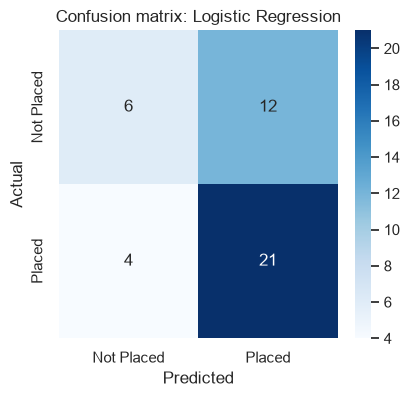

In [30]:
best_name = pipeline_results.sort_values("Accuracy", ascending=False).iloc[0]["Model"]
best_predictions = fitted[best_name][1]
print(f"Classification report for {best_name}:\n")
print(classification_report(y_test, best_predictions))

labels = ["Not Placed", "Placed"]
matrix = confusion_matrix(y_test, best_predictions, labels=labels)
plt.figure(figsize=(4.5, 4))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion matrix: {best_name}")
plt.savefig("outputs/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** on the test set Logistic Regression reaches 62.8% accuracy and the Decision Tree 55.8%. Always predicting `Placed` would already be correct for 25 of the 43 test students (58.1%), so the models are only slightly better than this baseline.

The models find `Placed` students well (recall 0.84 for Logistic Regression) but miss most `Not Placed` students (recall 0.33). The test set has only 43 students, so these numbers can change a lot with a different random split.

**Why accuracy is modest:** the dataset is small (215 rows), the signal in the features is weak, and only basic models are used. The aim of this lab is the preprocessing workflow, which is leakage-safe and reusable, not a high-accuracy model.

## 12. Analysis: comparing scaling techniques
Scaling changes how numeric features are measured. Distance-based models (KNN) and models trained by
gradient steps (Logistic Regression) can be sensitive to it, while tree models are not.

In [31]:
scaling_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN (k=7)": KNeighborsClassifier(n_neighbors=7),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}
scaling_options = {"No scaling": "none", "StandardScaler": "standard", "MinMaxScaler": "minmax"}

rows = []
for model_name, estimator in scaling_models.items():
    for option_name, option in scaling_options.items():
        pipeline = Pipeline([
            ("prep", make_preprocessor(SimpleImputer(strategy="median"), scaler=option)),
            ("clf", estimator)])
        mean_acc, std_acc = cv_accuracy(pipeline, df_clean[NUMERIC_COLS + CATEGORICAL_COLS],
                                        df_clean[TARGET])
        rows.append({"Model": model_name, "Scaling": option_name,
                     "CV Accuracy": round(mean_acc, 4), "Std": round(std_acc, 4)})

scaling_comparison = pd.DataFrame(rows)
scaling_comparison.pivot(index="Model", columns="Scaling", values="CV Accuracy")

Scaling,MinMaxScaler,No scaling,StandardScaler
Model,,,
Decision Tree,0.6419,0.6419,0.6419
KNN (k=7),0.5721,0.6465,0.6279
Logistic Regression,0.6884,0.6930,0.6930


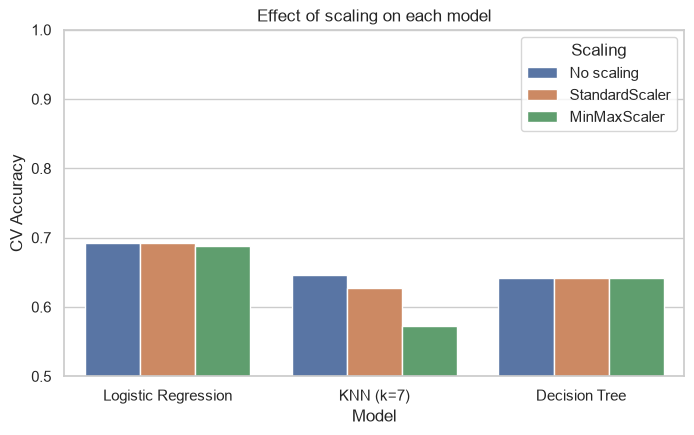

In [32]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=scaling_comparison, x="Model", y="CV Accuracy", hue="Scaling", ax=ax)
ax.set_ylim(0.5, 1.0)
ax.set_title("Effect of scaling on each model")
plt.savefig("outputs/scaling_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation**
- **Decision Tree:** identical accuracy (0.642) with all three options. Trees split on thresholds, so scaling does not change them.
- **KNN:** the most sensitive model. No scaling gives 0.647, StandardScaler 0.628 and MinMaxScaler 0.572. KNN depends on distances, so the scale of the features changes which neighbours are chosen.
- **Logistic Regression:** almost no change (0.688 to 0.693).

**Caution:** the percentage columns are already on similar scales (0 to 100), so scaling matters less than it would for features such as salary or age. Differences of a point or two are noise. The reliable lesson is *which* models are sensitive to scaling (KNN), not which scaler is "best".

## 13. Conclusion and learning outcomes
- Loaded and explored a dataset with Pandas and NumPy (shape, types, summary statistics, missing values, duplicates).
- Cleaned the data: removed duplicates, fixed inconsistent text, handled an invalid value and an outlier.
- Compared missing value techniques (drop, mean, median, KNN) and saw that salary is *structurally* missing and must not be imputed.
- Applied label encoding (binary columns, target) and one-hot encoding (multi-category column).
- Created new features and measured their impact instead of assuming they help.
- Ranked features with ANOVA F-score and mutual information, and tested top-k selection inside a pipeline.
- Built visualisations (histograms, count plots, box plots, scatter plot, correlation heatmap).
- Built a leakage-safe preprocessing pipeline with `ColumnTransformer` and `Pipeline`, evaluated with accuracy, precision, recall, F1-score and a confusion matrix.
- Compared scaling techniques across different model types.